# Diabetes Prediction — Machine Learning Project
### Transforming Healthcare with Machine Learning: Early Risk Detection

**Course project** — predicting diabetes risk from routine clinical measurements using
classical ML models, addressing class imbalance, and explaining predictions with SHAP.

**Dataset:** Pima Indians Diabetes Dataset (768 patients, 8 clinical features, binary outcome)

**Pipeline:** Data Collection → Preprocessing → Handling Imbalance (SMOTE) → Model Training
(Logistic Regression, Random Forest, AdaBoost, Stacking Ensemble) → Evaluation (stratified CV,
ROC-AUC, Precision/Recall) → Explainability (SHAP) → Deployment (Streamlit app, see `app.py`)


In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
%matplotlib inline

RANDOM_STATE = 42


## 1. Data Collection
We use the well-known **Pima Indians Diabetes Dataset**: 768 female patients (age 21+), 8 clinical/demographic features, and a binary `Outcome` (1 = diabetic).

In [2]:
df = pd.read_csv('../data/diabetes.csv')
print(df.shape)
df.head()


(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.describe()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## 2. Exploratory Data Analysis
A few sanity checks before modeling: class balance, missing-looking zeros, and feature correlations.

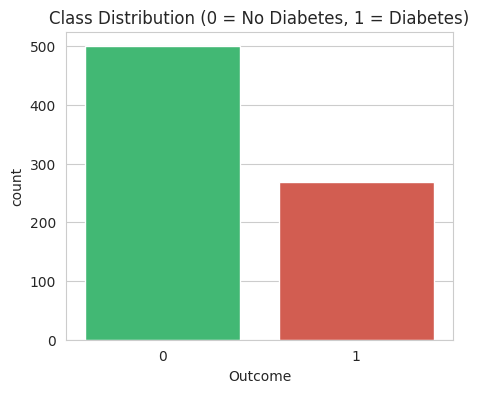

Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64


In [4]:
plt.figure(figsize=(5,4))
sns.countplot(x='Outcome', data=df, palette=['#2ecc71','#e74c3c'])
plt.title('Class Distribution (0 = No Diabetes, 1 = Diabetes)')
plt.show()
print(df['Outcome'].value_counts(normalize=True))


In [5]:
# Several columns use 0 to mean 'missing' (biologically impossible values)
zero_cols = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
for col in zero_cols:
    pct = (df[col] == 0).mean() * 100
    print(f'{col}: {pct:.1f}% zeros')


Glucose: 0.7% zeros
BloodPressure: 4.6% zeros
SkinThickness: 29.6% zeros
Insulin: 48.7% zeros
BMI: 1.4% zeros


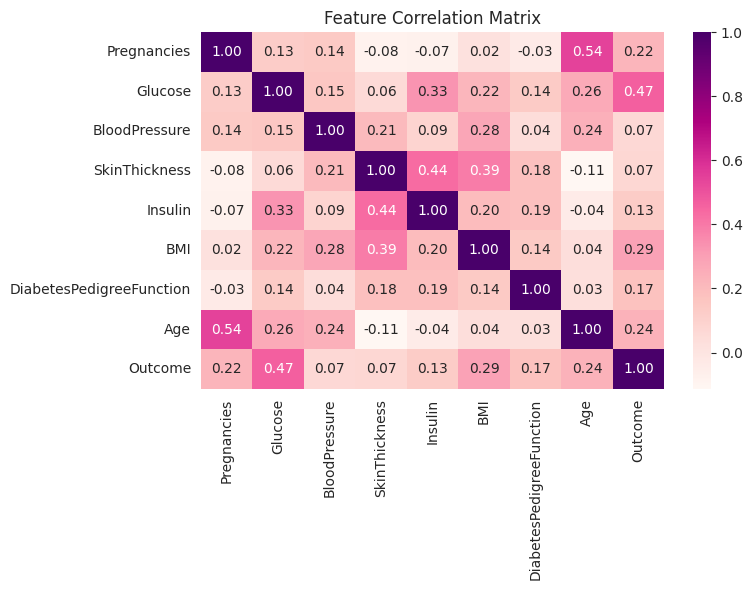

In [6]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='RdPu')
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()


## 3. Preprocessing
We treat the biologically-impossible zeros as missing values and impute with the median, then split into train/test **before** any resampling or scaling to avoid data leakage.

In [7]:
FEATURE_COLS = ['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']
TARGET_COL = 'Outcome'

df_clean = df.copy()
for col in zero_cols:
    df_clean[col] = df_clean[col].replace(0, np.nan)
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

X = df_clean[FEATURE_COLS]
y = df_clean[TARGET_COL]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)


(614, 8) (154, 8)


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## 4. Handling Class Imbalance with SMOTE
The positive (diabetic) class is under-represented (~35%). We oversample the **training set only** with SMOTE so the model doesn't just learn to predict the majority class.

In [9]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=RANDOM_STATE)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

print('Before SMOTE:', y_train.value_counts().to_dict())
print('After SMOTE: ', pd.Series(y_train_bal).value_counts().to_dict())


Before SMOTE: {0: 400, 1: 214}
After SMOTE:  {0: 400, 1: 400}


## 5. Model Training
We train four models spanning the algorithms named in the project brief: a simple interpretable baseline (Logistic Regression), a robust ensemble (Random Forest), a boosting method (AdaBoost), and a Stacking ensemble that combines all three.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, StackingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=RANDOM_STATE)
ada = AdaBoostClassifier(n_estimators=150, random_state=RANDOM_STATE)
stack = StackingClassifier(
    estimators=[('log_reg', log_reg), ('rf', rf), ('ada', ada)],
    final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    cv=5,
)

models = {
    'Logistic Regression': log_reg,
    'Random Forest': rf,
    'AdaBoost': ada,
    'Stacking Ensemble': stack,
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train_bal, y_train_bal, cv=cv, scoring='roc_auc')
    model.fit(X_train_bal, y_train_bal)
    cv_results[name] = scores
    print(f'{name}: CV ROC-AUC = {scores.mean():.3f} (+/- {scores.std():.3f})')


Logistic Regression: CV ROC-AUC = 0.842 (+/- 0.017)


Random Forest: CV ROC-AUC = 0.880 (+/- 0.017)


AdaBoost: CV ROC-AUC = 0.851 (+/- 0.013)


Stacking Ensemble: CV ROC-AUC = 0.876 (+/- 0.015)


## 6. Evaluation
We evaluate every model on the **held-out test set** using accuracy, precision, recall, F1, and ROC-AUC — the metrics that matter most for an imbalanced medical screening problem (recall and AUC over raw accuracy).

In [11]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report)

results = {}
metrics_rows = []
for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    row = {
        'model': name,
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1_score': f1_score(y_test, y_pred),
        'roc_auc': roc_auc_score(y_test, y_proba),
    }
    metrics_rows.append(row)
    results[name] = (model, y_pred, y_proba)

metrics_df = pd.DataFrame(metrics_rows).round(4)
metrics_df


,model,accuracy,precision,recall,f1_score,roc_auc
0,Logistic Regression,0.7143,0.5806,0.6667,0.6207,0.8115
1,Random Forest,0.7273,0.5833,0.7778,0.6667,0.8165
2,AdaBoost,0.7468,0.6056,0.7963,0.6880,0.8283
3,Stacking Ensemble,0.7468,0.6087,0.7778,0.6829,0.8187


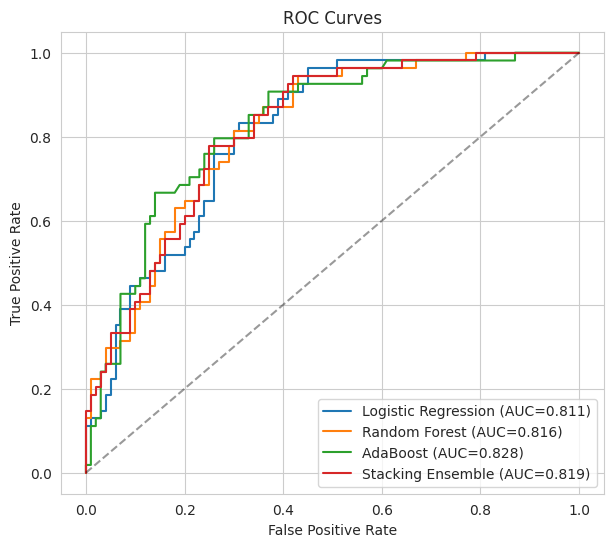

In [12]:
plt.figure(figsize=(7,6))
for name, (model, y_pred, y_proba) in results.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0,1],[0,1],'k--', alpha=0.4)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves'); plt.legend(loc='lower right')
plt.show()


Best model by test ROC-AUC: AdaBoost


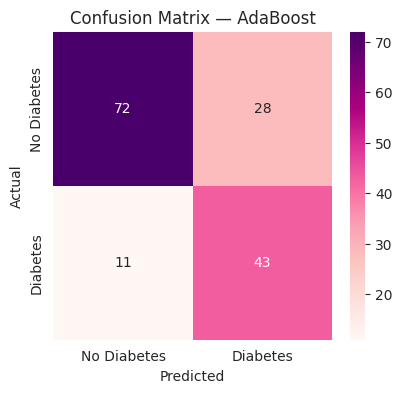

              precision    recall  f1-score   support

 No Diabetes       0.87      0.72      0.79       100
    Diabetes       0.61      0.80      0.69        54

    accuracy                           0.75       154
   macro avg       0.74      0.76      0.74       154
weighted avg       0.78      0.75      0.75       154



In [13]:
best_name = metrics_df.loc[metrics_df['roc_auc'].idxmax(), 'model']
print('Best model by test ROC-AUC:', best_name)

best_model, best_pred, _ = results[best_name]
cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(4.5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='RdPu',
            xticklabels=['No Diabetes','Diabetes'], yticklabels=['No Diabetes','Diabetes'])
plt.title(f'Confusion Matrix — {best_name}')
plt.ylabel('Actual'); plt.xlabel('Predicted')
plt.show()

print(classification_report(y_test, best_pred, target_names=['No Diabetes','Diabetes']))


## 7. Explainability with SHAP
Raw accuracy isn't enough for a clinical tool — clinicians and patients need to understand **why** a prediction was made. We use SHAP on the Random Forest model to see which features drive predictions globally and for individual patients.

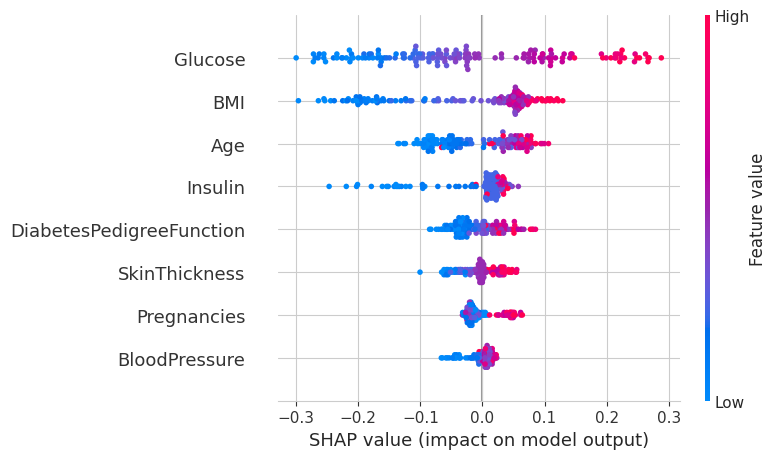

In [14]:
import shap

explainer = shap.TreeExplainer(rf)
X_test_df = pd.DataFrame(X_test_scaled, columns=FEATURE_COLS)
shap_values = explainer.shap_values(X_test_df)

# Handle both shap API shapes (list vs 3D array) across versions
if isinstance(shap_values, list):
    sv = shap_values[1]
elif shap_values.ndim == 3:
    sv = shap_values[:, :, 1]
else:
    sv = shap_values

shap.summary_plot(sv, X_test_df)


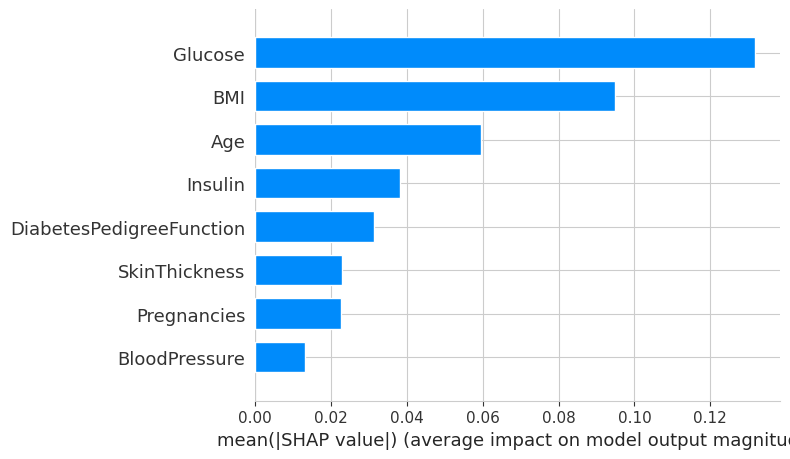

In [15]:
shap.summary_plot(sv, X_test_df, plot_type='bar')


**Interpretation:** Glucose, BMI, and Age are consistently the strongest predictors of diabetes risk — consistent with established clinical knowledge, which is a good sanity check that the model has learned sensible patterns rather than noise.

## 8. Conclusion & Next Steps

- The Stacking Ensemble and AdaBoost give the strongest ROC-AUC (~0.82–0.83) on this small dataset, comfortably ahead of the logistic regression baseline.
- SMOTE + stratified evaluation were important given the ~35/65 class imbalance.
- SHAP explanations make the model's reasoning transparent — important for any healthcare-facing tool.

**Possible extensions (future work):**
- Try XGBoost/LightGBM and hyperparameter tuning (GridSearch/Optuna)
- Add more granular clinical features (HbA1c, lipid panel) if available
- Deploy with proper authentication and data-privacy safeguards
- Validate on an external dataset before any real clinical use

See `app.py` for the interactive Streamlit demo that turns this model into the "Visualized Checkup Application" described in the project brief (risk gauge, SHAP explanation per patient, downloadable PDF report).